In [1]:
import numpy as np
import matplotlib.pyplot as plt
import toolbox as funcs
import pickle
import math
from sumrate_max import *

In [2]:
area_params = {"delta_h": 10 # height difference
                    , "area": 10  # lxl Service Area
                    , "bandwidth": 20e6
                    , "L":1  # APs
                    , "N":2  # antennas per AP
                    , "K": 2  # UEs
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 8  # Shadow fading LoS (dB)
                    , "AP_pos_rand": False
                                     }

sim_params = {"setups": 1000,
                     "batch":200,
                     "v":-1,
                     "d": 0,   #rician factor (0: no LoS component)
                     "norm_type" : np.inf,
                     "tests" :50
                    }

In [3]:
L = area_params["L"]
N = area_params["N"]
K = area_params["K"]
tests = sim_params["tests"]

filename = f"cdf50_p_max10_L1N2K2.pkl"
cdf_results = pickle.load(open(filename, "rb"))
invZ = cdf_results['invZ']
sumrate_hsdmS = cdf_results['sumrate_hsdmS']
sumrate_hsdmR = cdf_results['sumrate_hsdmR']
sumrate_hsdmC = cdf_results['sumrate_hsdmC']
sumrate_bcd = cdf_results['sumrate_bcd']
sumrate_maxPow = cdf_results['sumrate_maxPow']

rates_hsdmS = cdf_results['rates_hsdmS']
rates_hsdmR = cdf_results['rates_hsdmR']
rates_bcd = cdf_results['rates_bcd']

# p_bcd = cdf_results['p_bcd']
# p_hsdmR = cdf_results['p_hsdmR']

# gamma_S = cdf_results['gamma_S']
# gamma_R = cdf_results['gamma_R']

sumrate_maxPow = np.array(sumrate_maxPow).flatten()

In [9]:
# print(invZ)
# print(sum(invZ))

filename = f"cdf50_p_max10_L1N2K2.pkl"
cdf_Mu = pickle.load(open(filename, "rb"))
M_list = np.array(cdf_Mu['M_list'])
u_list = np.array(cdf_Mu['u_list'])
rates_hsdmR = np.array(rates_hsdmR)
rates_hsdmS = np.array(rates_hsdmS)

i=34
p_max = 10

M = M_list[i,:,:]
u = u_list[i,:,:]

print(np.exp(rates_hsdmR[i,:])-1)
print(np.exp(rates_hsdmS[i,:])-1)

pow_hsdmR = power_fixpoint(p_max, 2, M, u, np.exp(rates_hsdmR[i,:])-1)
pow_hsdmS = power_fixpoint(p_max, 2, M, u, np.exp(rates_hsdmS[i,:])-1)

# print(M_list[i,:,:])
print(sumrate_hsdmR[i]/np.log(2))
print(sumrate_hsdmS[i]/np.log(2))
# print(p_hsdmR[:,i])
# print(sumrate_bcd[i])
# print(p_bcd[:,i])

print(pow_hsdmR)
print(pow_hsdmS)


[0.74743769 0.19347693]
[0.7473397  0.19354358]
1.0604116964792385
1.0604113536746904
[[ 4.0469855]
 [10.1745283]]
[[ 3.97568641]
 [10.00001157]]


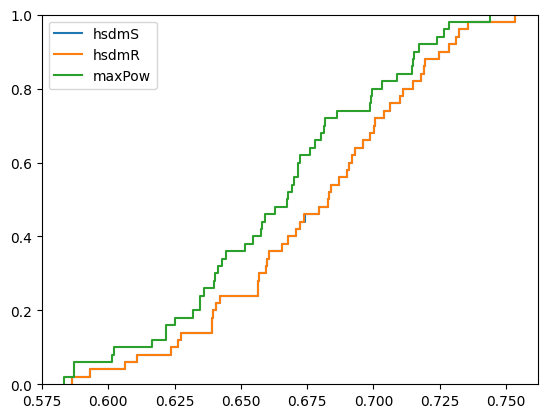

In [6]:
fig, ax = plt.subplots()
ax.ecdf(sumrate_hsdmS, label='hsdmS')
ax.ecdf(sumrate_hsdmR, label='hsdmR')
# ax.ecdf(sumrate_hsdmC, label='hsdmC')
# ax.ecdf(sumrate_bcd, label='bcd')
ax.ecdf(sumrate_maxPow, label='maxPow')

ax.legend()

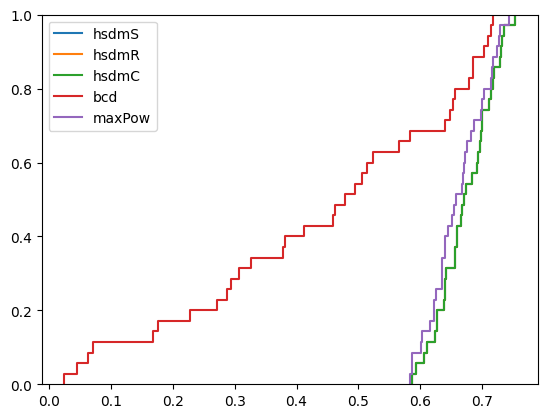

In [7]:
invZ_hsdmS = [sumrate for sumrate, inv in zip(sumrate_hsdmS, invZ) if  not inv]
invZ_hsdmR = [sumrate for sumrate, inv in zip(sumrate_hsdmR, invZ) if not inv]
invZ_hsdmC = [sumrate for sumrate, inv in zip(sumrate_hsdmC, invZ) if not inv]
invZ_bcd = [sumrate for sumrate, inv in zip(sumrate_bcd, invZ) if not inv]
invZ_maxPow = [sumrate for sumrate, inv in zip(sumrate_maxPow, invZ) if not inv]

fig, ax = plt.subplots()
ax.ecdf(invZ_hsdmS, label='hsdmS')
ax.ecdf(invZ_hsdmR, label='hsdmR')
ax.ecdf(invZ_hsdmC, label='hsdmC')
ax.ecdf(invZ_bcd, label='bcd')
ax.ecdf(invZ_maxPow, label='maxPow')

ax.legend()


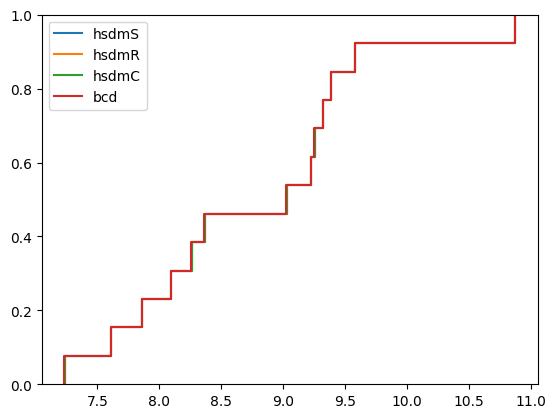

In [30]:
invZ_hsdmS = [sumrate for sumrate, inv in zip(sumrate_hsdmS, invZ) if inv]
invZ_hsdmR = [sumrate for sumrate, inv in zip(sumrate_hsdmR, invZ) if inv]
invZ_hsdmC = [sumrate for sumrate, inv in zip(sumrate_hsdmC, invZ) if inv]
invZ_bcd = [sumrate for sumrate, inv in zip(sumrate_bcd, invZ) if inv]
invZ_maxPow = [sumrate for sumrate, inv in zip(sumrate_maxPow, invZ) if inv]

fig, ax = plt.subplots()
ax.ecdf(invZ_hsdmS, label='hsdmS')
ax.ecdf(invZ_hsdmR, label='hsdmR')
ax.ecdf(invZ_hsdmC, label='hsdmC')
ax.ecdf(invZ_bcd, label='bcd')
# ax.ecdf(invZ_maxPow, label='maxPow')

ax.legend()
